In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import torch
import torchvision
import torchvision.transforms as transforms

# Define which device to use for computations
# If you have gpu, use 'cuda'
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("You train on {}".format(device))

You train on cuda


### Prepare data for training and testing

In [4]:
# Local Storage
target_size = (28, 28)
transform =  transforms.Compose([transforms.ToTensor(), 
                                 transforms.Resize(target_size), # Resizes image
                                 transforms.Normalize(mean=(0.5), std=(0.5)) # scales to [-1.0, 1.0]
                                 ])

mnist_train = torchvision.datasets.ImageFolder(root="mnist-png-format/train", transform=transform)
mnist_test = torchvision.datasets.ImageFolder(root="mnist-png-format/test", transform=transform)

print("Size of MNIST Training Set =" ,len(mnist_train))
print("Size of MNIST Testing Set =" ,len(mnist_test))

Size of MNIST Training Set = 60000
Size of MNIST Testing Set = 10000


In [5]:
# Defining Data Loaders with batch size 64
from torch.utils.data import DataLoader
batch_size = 64
train_loader = DataLoader(mnist_train, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(mnist_test, batch_size=batch_size, shuffle=True)

## Model Design
### CNN Model

In [6]:
import torch.nn as nn
    
class CNN_model(nn.Module):
    
    def __init__(self):
        super(CNN_model, self).__init__()
        self.conv_layers = nn.Sequential(
            # input size: 3x28x28
            nn.Conv2d(in_channels=3, out_channels=6, kernel_size=5), # Conv1
            nn.LeakyReLU(),
            # output: 6x24x24 (because kernel_size=5, stride=1 and no padding)
            
            nn.Conv2d(in_channels=6, out_channels=12, kernel_size=5), # Conv2
            nn.LeakyReLU(),
            # output: 12x20x20 (because kernel_size=5, stride=1 and no padding)
            
            nn.Conv2d(in_channels=12, out_channels=24, kernel_size=5), # Conv3
            nn.LeakyReLU(),
            # output: 24x16x16 (because kernel_size=5, stride=1 and no padding)
            nn.MaxPool2d(kernel_size=2, stride=2)
            # output: 24x8x8
        )
        self.linear_layer = nn.Linear(24*8*8, 10) # map Flatten output of conv layers(24*8*8=1536) to number of classes(10)
    
    def forward(self, input):
        output = self.conv_layers(input) # NO FLATTENING HERE, expected input is of dimension batch_size x n_channels x im_height x im_width
        output = output.view(output.size()[0], -1) # Flatten to a vector before passing to a linear layer
        output = self.linear_layer(output)
        return output

### Training & Evaluation

In [7]:
# Training loop in each epoch on training set
def train_epoch(model, train_dataloader, optimizer, loss_fn):
    losses = []
    correct_predictions = 0
    
    # Iterate mini batches over training dataset
    for images, labels in train_dataloader:
        images = images.to(device)
        labels = labels.to(device)
        
        # Run predictions
        output = model(images)
        
        # Set gradients to zero
        optimizer.zero_grad()
        
        # Compute loss
        loss = loss_fn(output, labels)
        
        # Backpropagate (compute gradients)
        loss.backward()
        
        # Make an optimization step (update parameters)
        optimizer.step()
        
        # Log metrics
        losses.append(loss.item())
        predicted_labels = output.argmax(dim=1)
        correct_predictions += (predicted_labels == labels).sum().item()
        
    # Return mean loss value and accuracy for each iteration
    mean_loss = np.array(losses).mean()
    model_accuracy = 100.0 * correct_predictions / len(train_dataloader.dataset)
    return mean_loss, model_accuracy

# Evaluation loop in each epoch on testing set
def evaluate_epoch(model, eval_dataloader, loss_fn):
    losses = []
    correct_predictions = 0
    
    with torch.no_grad():
        for images, labels in eval_dataloader:
#         for images, labels in tqdm(eval_dataloader):
            images = images.to(device)
            labels = labels.to(device)
            
            # Run predictions
            output = model(images)
            
            # Compute loss
            loss = loss_fn(output, labels)
            
            # Log metrics
            losses.append(loss.item())
            predicted_labels = output.argmax(dim=1)
            correct_predictions += (predicted_labels == labels).sum().item()
            
            
    # Return mean loss value and accuracy for each iteration
    mean_loss = np.array(losses).mean()
    model_accuracy = 100.0 * correct_predictions / len(eval_dataloader.dataset)
    return mean_loss, model_accuracy

# Training and Performing validation
def train(model, train_dataloader, val_dataloader, optimizer, n_epochs, loss_function):
    # We will monitor loss functions as the training progresses
    train_losses = []
    val_losses = []
    train_accuracies = []
    val_accuracies = []

    for epoch in range(n_epochs):
        model.train()
        train_loss, train_accuracy = train_epoch(model, train_dataloader, optimizer, loss_fn)
        model.eval()
        val_loss, val_accuracy = evaluate_epoch(model, val_dataloader, loss_fn)
        train_losses.append(train_loss)
        val_losses.append(val_loss)
        train_accuracies.append(train_accuracy)
        val_accuracies.append(val_accuracy)
        print('Epoch {}/{}: train_loss: {:.4f}, train_accuracy: {:.4f}, val_loss: {:.4f}, val_accuracy: {:.4f}'.format(epoch+1, n_epochs,
                                                                                                      train_losses[-1],
                                                                                                      train_accuracies[-1],
                                                                                                      val_losses[-1],
                                                                                                      val_accuracies[-1]))
    return train_losses, train_accuracies, val_losses, val_accuracies

### Plotting Function

In [8]:
def plot_L_A(train_losses, val_losses, train_accuracies, val_accuracies):
    plt.subplots(figsize=(15,5))
    plt.suptitle('Training and validation loss and accuracy')
    plt.subplot(121)
    plt.plot(np.arange(len(train_losses)), train_losses)
    plt.plot(np.arange(len(val_losses)), val_losses)
    plt.legend(['Train_Loss', 'Val_Loss'])
    plt.xlabel('Epoch')
    plt.ylabel('Loss Value')
    plt.title('Train & Val Loss')

    plt.subplot(122)
    plt.plot(np.arange(len(train_accuracies)), train_accuracies)
    plt.plot(np.arange(len(val_accuracies)), val_accuracies)
    plt.legend(['Train_Acc', 'Val_Acc'])
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.title('Train & Val Accuracy')

### Train the model and report the results

#### Optimizing the Learning Rate

In [ ]:
model_conv = CNN_model()
model_conv = model_conv.to(device)
learning_rate = 0.001
optimizer = torch.optim.Adam(model_conv.parameters(), lr=learning_rate)
n_epochs = 25
loss_fn = nn.CrossEntropyLoss()

Learning Rate: 0.001
Epoch 1/20: train_loss: 0.1637, train_accuracy: 94.9417, val_loss: 0.0523, val_accuracy: 98.3400
Epoch 2/20: train_loss: 0.0541, train_accuracy: 98.3550, val_loss: 0.0392, val_accuracy: 98.8200
Epoch 3/20: train_loss: 0.0413, train_accuracy: 98.7283, val_loss: 0.0347, val_accuracy: 98.8600
Epoch 4/20: train_loss: 0.0323, train_accuracy: 98.9950, val_loss: 0.0347, val_accuracy: 99.0000
Epoch 5/20: train_loss: 0.0268, train_accuracy: 99.1767, val_loss: 0.0401, val_accuracy: 98.7800
Epoch 6/20: train_loss: 0.0220, train_accuracy: 99.3200, val_loss: 0.0381, val_accuracy: 98.8500
Epoch 7/20: train_loss: 0.0185, train_accuracy: 99.4167, val_loss: 0.0289, val_accuracy: 99.0400
Epoch 8/20: train_loss: 0.0163, train_accuracy: 99.4867, val_loss: 0.0382, val_accuracy: 98.8200
Epoch 9/20: train_loss: 0.0138, train_accuracy: 99.5517, val_loss: 0.0426, val_accuracy: 98.7600
Epoch 10/20: train_loss: 0.0125, train_accuracy: 99.5917, val_loss: 0.0437, val_accuracy: 98.8500
Epoch 11

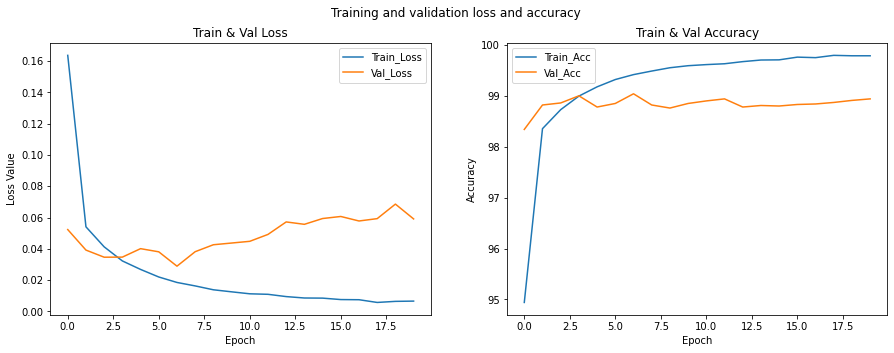

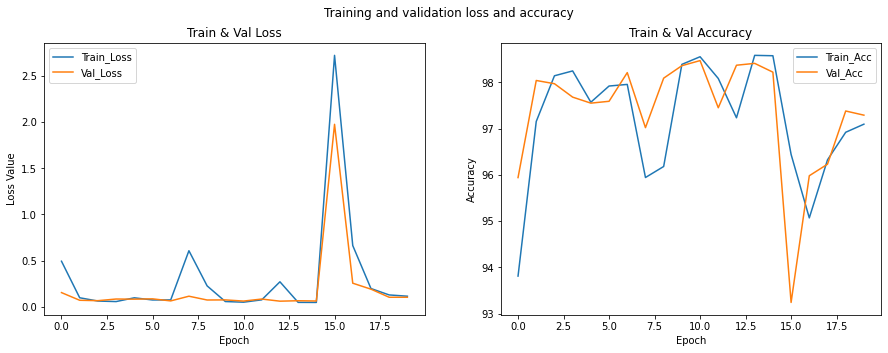

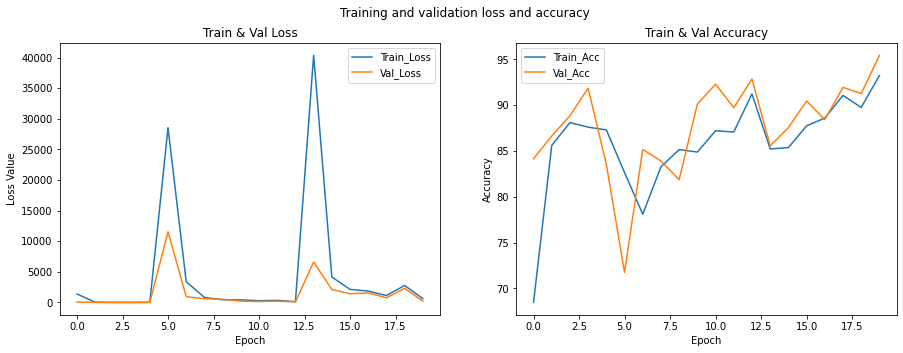

In [10]:
n_epochs = 20
learning_rate_t = [0.001,0.01,0.1] #Learning Rate

val_acc_list = []
train_acc_list = []

for i in range (3):
    model_conv_t = CNN_model()
    model_conv_t = model_conv_t.to(device)
    optimizer = torch.optim.Adam(model_conv_t.parameters(), lr=learning_rate_t[i])
    loss_fn = nn.CrossEntropyLoss()
    print("Learning Rate:", learning_rate_t[i])
    train_losses_t, train_accuracies_t, val_losses_t, val_accuracies_t = train (model_conv_t, train_loader, test_loader, optimizer, n_epochs, loss_fn)
    val_acc_list.append(val_accuracies_t[-1])
    train_acc_list.append(train_accuracies_t[-1])
    plot_L_A(train_losses_t, val_losses_t, train_accuracies_t, val_accuracies_t)

In [11]:
result = {'Learning Rate': learning_rate_t,'Training Accuracy': train_acc_list, 'Validation Accuracy': val_acc_list}
table = pd.DataFrame(result)
table

,Learning Rate,Training Accuracy,Validation Accuracy
0,0.001,99.786667,98.94
1,0.010,97.095000,97.29
2,0.100,93.243333,95.45


In [12]:
learning_rate_opt = learning_rate_t[np.argmax(val_acc_list)]
print("The optimum Learning Rate is:", learning_rate_opt)

The optimum Learning Rate is: 0.001


### Optimizing number of training iterations(Epochs)

In [13]:
n_epochs = 30

model_conv_t = CNN_model()
model_conv_t = model_conv_t.to(device)
optimizer = torch.optim.Adam(model_conv_t.parameters(), lr=learning_rate_opt)
loss_fn = nn.CrossEntropyLoss()

train_losses_t, train_accuracies_t, val_losses_t, val_accuracies_t = train (model_conv_t, train_loader, test_loader, optimizer, n_epochs, loss_fn)

Epoch 1/30: train_loss: 0.1619, train_accuracy: 95.0333, val_loss: 0.0635, val_accuracy: 98.0600
Epoch 2/30: train_loss: 0.0525, train_accuracy: 98.3617, val_loss: 0.0408, val_accuracy: 98.7600
Epoch 3/30: train_loss: 0.0395, train_accuracy: 98.7267, val_loss: 0.0345, val_accuracy: 98.8300
Epoch 4/30: train_loss: 0.0313, train_accuracy: 99.0533, val_loss: 0.0305, val_accuracy: 99.0800
Epoch 5/30: train_loss: 0.0260, train_accuracy: 99.1583, val_loss: 0.0395, val_accuracy: 98.8300
Epoch 6/30: train_loss: 0.0226, train_accuracy: 99.2867, val_loss: 0.0337, val_accuracy: 98.9900
Epoch 7/30: train_loss: 0.0197, train_accuracy: 99.3717, val_loss: 0.0347, val_accuracy: 98.9900
Epoch 8/30: train_loss: 0.0170, train_accuracy: 99.4400, val_loss: 0.0325, val_accuracy: 99.0100
Epoch 9/30: train_loss: 0.0141, train_accuracy: 99.5233, val_loss: 0.0350, val_accuracy: 98.9700
Epoch 10/30: train_loss: 0.0134, train_accuracy: 99.5650, val_loss: 0.0360, val_accuracy: 99.0100
Epoch 11/30: train_loss: 0.01

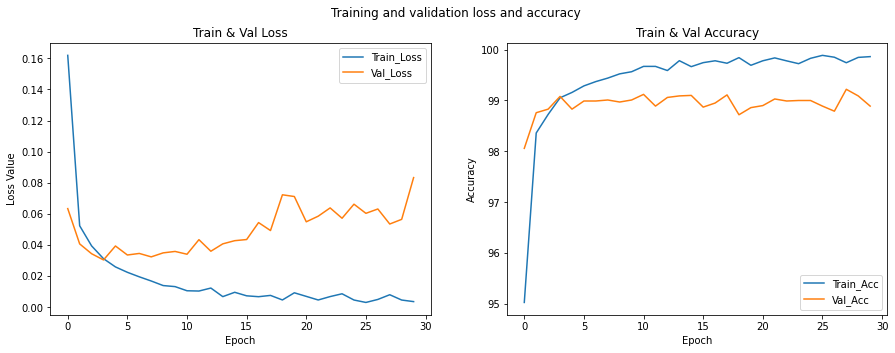

In [14]:
plot_L_A(train_losses_t, val_losses_t, train_accuracies_t, val_accuracies_t)

#### According to the above plots, we can approximately consider the optimum Epoch number = 4

### Training and Testing based on the best parameters

In [20]:
n_epochs_opt = 4

model_conv_opt = CNN_model()
model_conv_opt = model_conv_opt.to(device)
optimizer = torch.optim.Adam(model_conv_opt.parameters(), lr=learning_rate_opt)
loss_fn = nn.CrossEntropyLoss()

train_losses_opt, train_accuracies_opt, val_losses_opt, val_accuracies_opt = train (model_conv_opt, train_loader, test_loader, optimizer, n_epochs_opt, loss_fn)

Epoch 1/4: train_loss: 0.1617, train_accuracy: 95.2083, val_loss: 0.0605, val_accuracy: 97.9700
Epoch 2/4: train_loss: 0.0526, train_accuracy: 98.3800, val_loss: 0.0407, val_accuracy: 98.6900
Epoch 3/4: train_loss: 0.0379, train_accuracy: 98.8200, val_loss: 0.0367, val_accuracy: 98.8500
Epoch 4/4: train_loss: 0.0315, train_accuracy: 98.9833, val_loss: 0.0331, val_accuracy: 99.0000


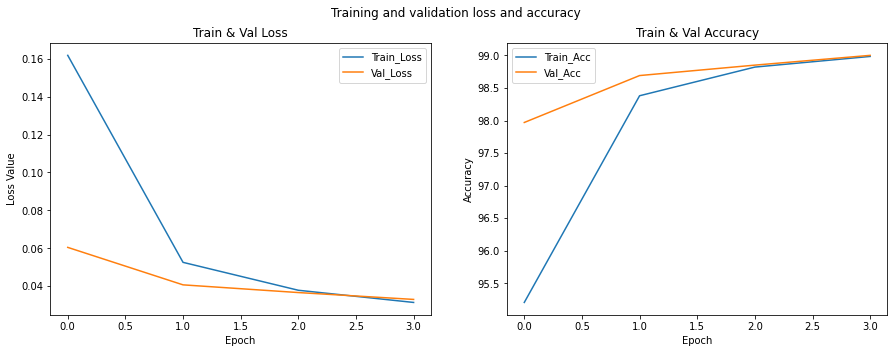

In [21]:
plot_L_A(train_losses_opt, val_losses_opt, train_accuracies_opt, val_accuracies_opt) 

In [22]:
print("Weight size of Conv 1:", model_conv_opt.conv_layers[0].weight.size())
print("Weight size of Conv 2:", model_conv_opt.conv_layers[2].weight.size())
print("Weight size of Conv 3:", model_conv_opt.conv_layers[4].weight.size())

Weight size of Conv 1: torch.Size([6, 3, 5, 5])
Weight size of Conv 2: torch.Size([12, 6, 5, 5])
Weight size of Conv 3: torch.Size([24, 12, 5, 5])


In [23]:
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

In [24]:
print('This ConvNet contains: {} parameters'.format(count_parameters(model_conv_opt)))

This ConvNet contains: 24862 parameters
